# CP1 · Reproduksi x-FUSegNet

**Lima model FUSegNet · native 512×512 · rata-rata probabilitas sebelum threshold 0.5.**

OOF adalah validasi internal dari satu model fold per gambar. **Skor test challenge tidak tersedia** karena 200 mask test privat tidak ada di dataset lokal.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/xfusegnet.json').exists())
sys.path.insert(0,str(ROOT/'scripts'))
import matplotlib.pyplot as plt
from IPython.display import display,HTML
from build_xfuseg_analysis import load_context,plot_curves,plot_oof,plot_gallery
from cp1_analysis import configure_style
%matplotlib inline
configure_style()
c=load_context(ROOT/'outputs/xfusegnet/cp1-xfusegnet-01')
def table(df):
    display(HTML(df.to_html(index=False,border=0,float_format=lambda v:f'{v:.4f}')))
print('Diagnostic fixture:',c['metadata']['diagnostic_fixture'])
print('Split:',c['metadata']['split_fingerprint'])

Diagnostic fixture: False
Split: 93aac316e596dcc34b8d55174ea1b10a564cb07f7398e4616c78409552076e2a


## 1 · Metode dan kesetaraan kode

Loop numerik dari `xfusegnet_train.py` pada revisi penulis yang dipin dieksekusi langsung; hook menambah status, checkpoint resume, dan pencatatan. Arsitektur, augmentasi x-FUSegNet, loss, optimizer, scheduler, dan kebijakan checkpoint sumber dipertahankan. Python shuffle seed 42 diikuti `KFold(5, shuffle=False)`. Global torch/numpy seed 42 ditambahkan untuk reproducibility; RNG berlanjut antar-fold. Urutan file asli penulis tidak tersedia. Pool 1.010 gambar berlabel berasal dari 810 provided-train + 200 provided-validation, masing-masing fold 808/202; test 200 terpisah.

fold,train_images,oof_images,epochs,selected_epoch,training_minutes,peak_cuda_gib,oof_identical_rgb_to_train
1,808,202,124,94,233.0022,7.1647,12
2,808,202,200,198,330.2459,7.1740,10
3,808,202,156,126,296.1359,7.1608,9
4,808,202,129,99,303.7550,7.1641,4
5,808,202,111,81,191.0661,7.1715,10


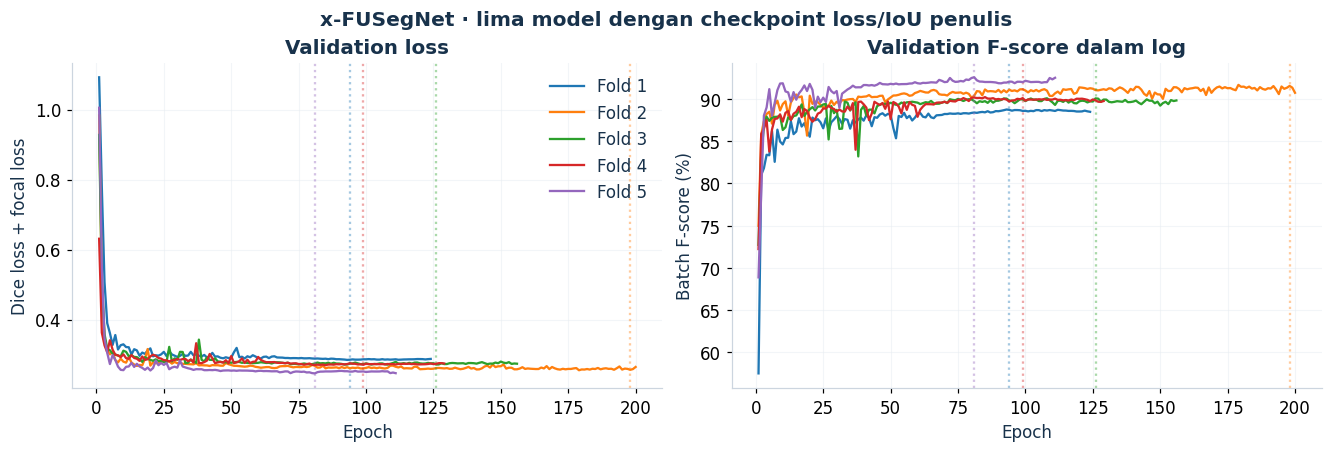

In [2]:
table(c['folds'][['fold','train_images','oof_images','epochs','selected_epoch','training_minutes','peak_cuda_gib','oof_identical_rgb_to_train']])
plot_curves(c)
plt.show()

## 2 · Evaluasi OOF internal

Setiap gambar dievaluasi oleh model yang tidak memakai filename tersebut dalam training fold-nya. Checkpoint dipilih pada validation fold yang sama, sehingga ini hasil validasi internal. OOF **bukan hasil ensemble lima model pada independent test set**. Mask training tetap dibagi 255 termasuk nilai 32/255 pada satu mask. Untuk metrik biner/PFOM saja, GT memakai threshold 0.5. PFOM empty-edge 1/0; proxy sentinel 2 terpisah.

OOF image Dice: 88.03%
OOF data Dice: 92.72%
OOF mean PFOM: 0.7315
Sentinel-2 proxy: 0.7780


fold,image_dice,data_dice,pfom
1,0.8495,0.9100,0.7044
2,0.8899,0.9370,0.7366
3,0.8766,0.9236,0.7162
4,0.8747,0.9219,0.7279
5,0.9109,0.9404,0.7723


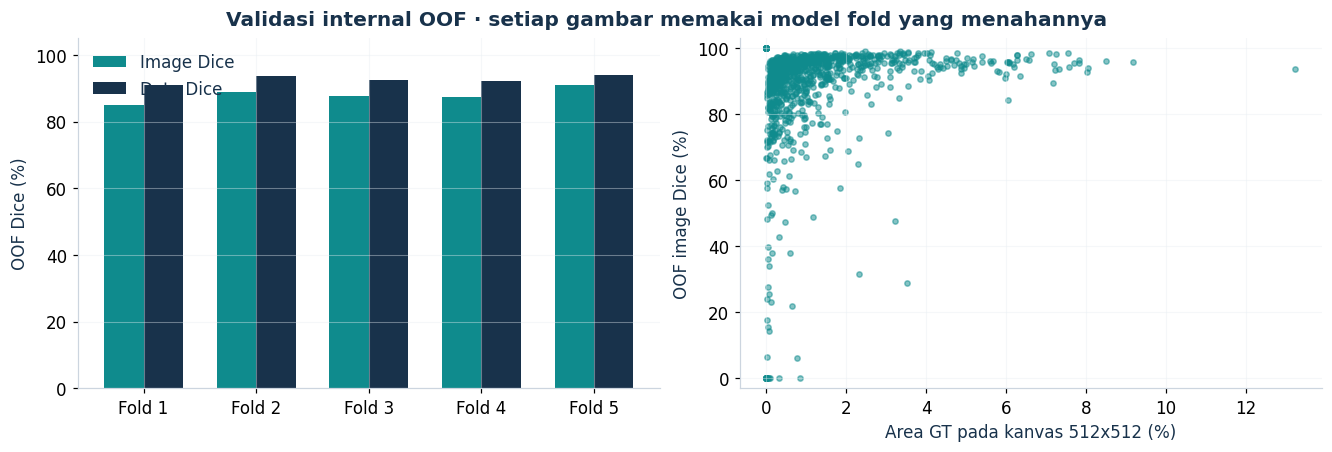

In [3]:
m=c['metadata'];s=m['oof_evaluation']['offline_hard_line']
print('OOF image Dice:',f"{s['image_based']['dice']*100:.2f}%")
print('OOF data Dice:',f"{s['data_based']['dice']*100:.2f}%")
print('OOF mean PFOM:',f"{m['oof_mean_pfom']:.4f}")
print('Sentinel-2 proxy:',f"{m['oof_sentinel2_proxy']:.4f}")
table(c['folds'][['fold','image_dice','data_dice','pfom']])
plot_oof(c)
plt.show()

## 3 · Prediksi OOF

Lima nama ditetapkan sebelum training: gambar pertama validation masing-masing fold. Hijau TP, merah FP, biru FN. Tidak ada pemilihan ulang berdasarkan hasil model.

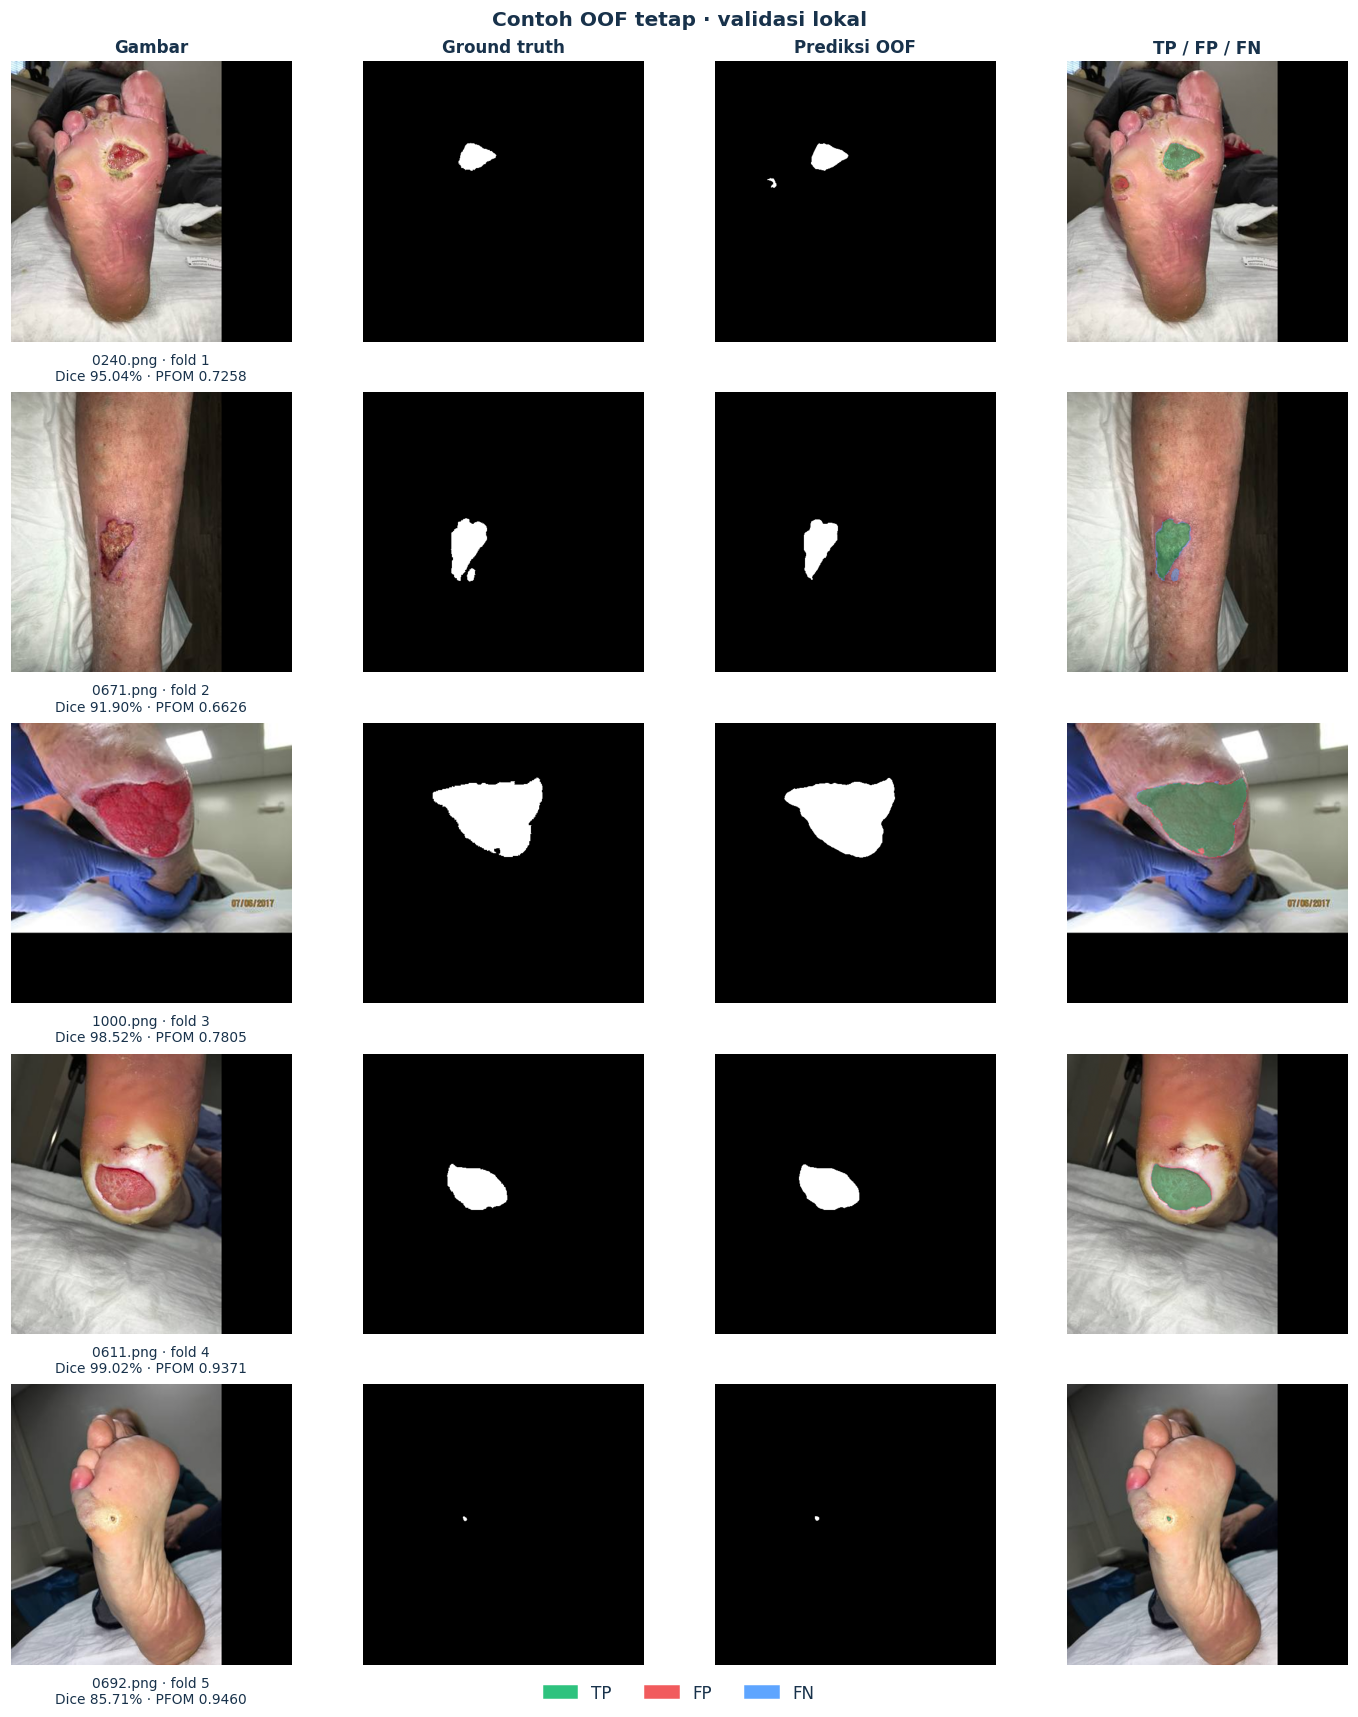

In [4]:
plot_gallery(c,'oof')
plt.show()

## 4 · Ensemble pada 200 gambar test

Setiap gambar diprediksi oleh lima checkpoint terpilih, kemudian `np.mean` pada lima probability map float32 dan threshold `>=0.5`. Semua mean dan PNG diperiksa ulang. GT test tidak tersedia; galeri berikut **tidak memiliki skor Dice/PFOM**. Lima nama contoh ditetapkan dari urutan filename sebelum training. Angka **89.23%** dalam paper adalah skor test challenge milik penulis; angka itu tidak diverifikasi oleh validasi OOF lokal.

Gambar test dengan ensemble: 200
Official test metrics: None


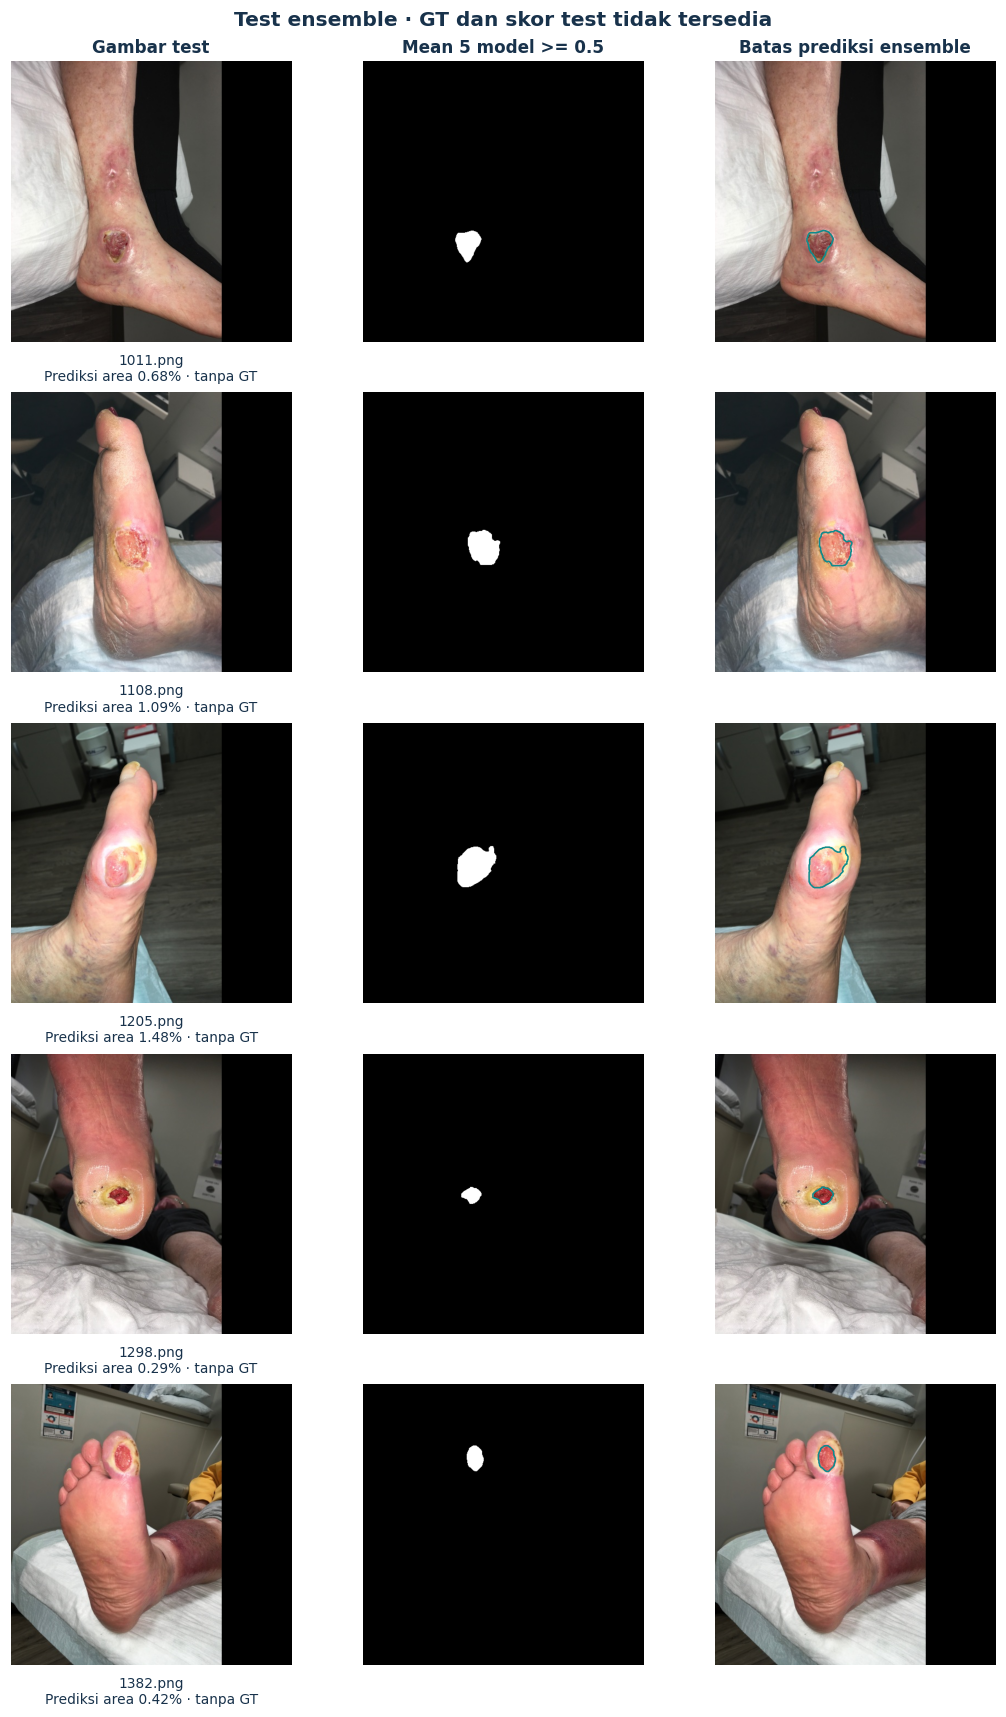

In [5]:
print('Gambar test dengan ensemble:',len(c['test']))
print('Official test metrics:',c['metadata']['official_test_metrics'])
plot_gallery(c,'test')
plt.show()

## 5 · Batas interpretasi dan referensi

Sumber memiliki duplikasi RGB antar-fold yang dipertahankan agar mengikuti protokol sumber; jumlahnya dilaporkan per fold. Independensi pasien belum terverifikasi. Fold asli penulis, global seed asli, dan evaluasi test privat belum tersedia. Skor OOF 512×512 tidak dibandingkan langsung sebagai peningkatan atas test Chronic Wound 224×224. Reproduksi x-FUSegNet merupakan bagian reproduksi, belum merupakan novelty CP2.

[Paper §3.2.4](https://arxiv.org/abs/2305.02961v2) · [Kode penulis](https://github.com/mrinal054/FUSegNet) · [Dataset FUSeg](https://github.com/uwm-bigdata/wound-segmentation/tree/master/data/Foot%20Ulcer%20Segmentation%20Challenge) · [Protokol lokal](../docs/xfusegnet.md)